# 3. Second-degree-moment inversion

The **second-degree moments (SDMs)** summarize a rupture by six numbers: its duration, its size and shape (an
ellipse on the fault), and how its centroid moves (McGuire, 2004). Each apparent duration τc(s) measured at a
station follows from them as τc(s) = 2√(G m₂), where a row of the matrix G holds the ray's slowness on the fault.
From the SDMs come the physical parameters:

| Symbol | Meaning |
|---|---|
| τc | characteristic duration (s) |
| L_c, W_c | characteristic length and width: semi-axes of the ellipse (m) |
| θ^Lc | direction of the long axis on the fault (° from strike) |
| \|v0\|, θ^v0 | speed (m/s) and direction (°) of the centroid motion |
| D | directivity ratio, 0 for a bilateral rupture, 1 for a unilateral one |
| Δσ | static stress drop of a uniform elliptical crack (MPa) |

This notebook inverts the duration table of notebook 2:

1. the slowness matrix on the fault plane;
2. the deterministic solution (semidefinite programming, SDP) on both nodal planes, which identifies the fault plane;
3. the hierarchical Bayesian inversion (BayesBay): 20 Markov chains sample the six SDMs **and** the data noise level;
4. posterior summary: medoid, MAP, 95 % highest-density intervals (HDIs) and stress drop;
5. the summary figure; 6. the corner plot; 7. the fit to the data.

In [1]:
import json
import os
import time

import numpy as np
import pandas as pd

from bayes2mt import bayesian, deterministic, geometry, io, moments, relloc, stressdrop
from bayes2mt.config import moment_from_mw
from bayes2mt.plotting import auto_panels, pearson_matrix, plot_corner, plot_sdm_summary, relative_offset, use_style

DATA = "data/event016"
event = json.load(open(f"{DATA}/event.json"))
table = io.read_tauc_table(f"{DATA}/tauc_table.csv")
vp, vs = event["vp_km_s"], event["vs_km_s"]
planes = {1: tuple(event["auxiliary_plane"]), 2: (event["strike"], event["dip"], event["rake"])}
print("font:", use_style())
print(f"{len(table)} apparent durations:", table.phase.value_counts().to_dict())

font: helvetica
88 apparent durations: {'S': 39, 'P': 34, 'SmS': 15}


## Step 1–2. Deterministic solution and the fault plane

The SDP finds the moments that fit the squared durations best while keeping the moment matrix positive
semidefinite (a physical rupture). It is run on both nodal planes of the focal mechanism; the plane with the clearly
higher variance reduction (by more than 10 points) is taken as the fault.

In [2]:
sdp1, sdp2, preferred = deterministic.compare_nodal_planes(table, planes[1][:2], planes[2][:2], vp, vs)
print(f"variance reduction: plane 1 ({planes[1][0]:.0f}/{planes[1][1]:.0f}) {sdp1.vr:.2f} %, "
      f"plane 2 ({planes[2][0]:.0f}/{planes[2][1]:.0f}) {sdp2.vr:.2f} %  -> fault plane: {preferred}")
if preferred is None:                 # no clear winner: keep the better-fitting plane, and say so
    preferred = 1 if sdp1.vr > sdp2.vr else 2
    print(f"the variance reductions differ by less than 10 points; plane {preferred} fits slightly better")
strike, dip, rake = planes[preferred]
sdp = sdp1 if preferred == 1 else sdp2
pd.Series(sdp.params).astype(float).round(4).to_frame("SDP")

variance reduction: plane 1 (12/81) 53.68 %, plane 2 (108/58) 86.81 %  -> fault plane: 2


,SDP
tauc,0.0432
Lc,222.1478
Wc,100.0034
vx,-1.1187
vy,3.1375
v0,3331.0000
rake,250.3768
angle,73.6667
dir_ratio,0.6477


## Step 3. Hierarchical Bayesian inversion

The six sampled values are a Cholesky-type parameterization that always gives a physical (positive
semidefinite) moment matrix; their uniform prior ranges and proposal widths are those of `bayesian.Priors()`
($\tau_c$ from 10 ms to 0.8 s). The noise standard deviation of the durations is sampled too (uniform between 0
and 0.05 s): this is what makes the inversion *hierarchical*. The run of this event in Seo et al. (2026) allowed
$\tau_c$ from 20 ms and a proposal width of 0.1 for $x_4$; both settings give the same posterior within sampling
variation. 20 chains × 1,000,000 iterations, burn-in 50,000, every 100th sample kept (190,000 samples);
about 3 minutes on 16 cores. R-hat close to 1 and large effective sample sizes (ESS) show that the chains agree.

In [3]:
G = geometry.slowness_matrix(table, strike, dip, vp, vs)
inversion = bayesian.build(G, table["tauc"])
t0 = time.perf_counter()
ensemble, per_chain = bayesian.run(inversion, n_iterations=1_000_000, n_jobs=min(20, os.cpu_count()))
runtime = time.perf_counter() - t0
diag = pd.DataFrame(bayesian.diagnostics(per_chain))
print(f"{len(ensemble):,} samples in {runtime / 60:.1f} min; max R-hat {diag['rhat'].max():.4f}, "
      f"min ESS {diag[['ess_bulk', 'ess_tail']].min().min():.0f}")
diag.round(4)

190,000 samples in 1.9 min; max R-hat 1.0013, min ESS 11285


,rhat,ess_bulk,ess_tail
m0,1.0007,19801.6800,55994.4695
m1,1.0001,120235.2671,149810.0532
m2,1.0004,33373.8399,82453.6372
m3,1.0011,14107.5001,44614.3519
m4,1.0013,11285.4617,33718.6175
m5,1.0012,12136.2762,22245.1612


## Step 4. Posterior summary

Three reference models: the **medoid** (the sample closest, on average, to all others; the representative model),
the **MAP** (the sample that fits the durations best) and the SDP solution. Uncertainties are 95 % HDIs, on the
circle for the two angles. The stress drop uses the uniform-stress-drop elliptical crack with semi-axes L_c and
W_c and slip along the focal-mechanism rake.

In [4]:
m2 = moments.cholesky_to_m2(ensemble.x)
post = moments.physical(m2)
pred = moments.predict_tauc(G, m2)                                  # every sample's predicted durations
vr = moments.variance_reduction(table["tauc"].to_numpy(), pred)
i_med, i_map = moments.medoid_index(m2), int(np.argmax(vr))
medoid, map_model = moments.physical(m2[i_med]), moments.physical(m2[i_map])
M0 = moment_from_mw(event["mw"])
for d in (post, medoid, map_model):
    d["stress_drop"] = stressdrop.stress_drop(M0, d["Lc"], d["Wc"], rake, d["angle"])
rows = {}
for k in ["tauc", "Lc", "Wc", "v0", "rake", "angle", "dir_ratio", "stress_drop"]:
    if k in ("rake", "angle"):
        h = moments.circular_hdi(post[k], modulus=360.0 if k == "rake" else 180.0)
        lo, hi = h[0, 0], h[-1, 1]
    else:
        lo, hi = moments.hdi(post[k])
    rows[k] = dict(medoid=float(medoid[k]), MAP=float(map_model[k]), hdi_low=lo, hdi_high=hi)
summary = pd.DataFrame(rows).T
summary.round(4)

,medoid,MAP,hdi_low,hdi_high
tauc,0.0454,0.0445,0.0426,0.0479
Lc,205.3579,210.1315,185.7591,229.4983
Wc,64.6959,85.9499,8.9094,108.0163
v0,2950.4986,3080.7782,2457.1055,3481.1237
rake,249.8738,250.6362,245.5158,254.5202
angle,73.0526,72.3359,66.2282,80.0019
dir_ratio,0.6528,0.6531,0.5474,0.7472
stress_drop,51.5808,29.5851,11.7508,961.7332


## Step 5. Summary figure

The layout of Fig. 4 of Seo et al. (2026). (a) Location of the target (beach ball; thick red arc = fault plane)
relative to its EGF (red circle); (b) the best-fit solution, i.e. the deterministic (SDP) solution of steps 1–2
(black ellipse, blue centroid-motion arrow), over 500 posterior samples (gray, light blue), seen on the fault
(horizontal axis along strike, vertical axis along dip, downward); (c) observed (colored) and predicted (black)
apparent durations of direct S and SmS against azimuth, the predictions being those of the best-fit solution in
(b); (d) the same for direct P.

best-fit (SDP) solution: Lc 222.1 m, Wc 100.0 m, D 0.648, variance reduction 86.8 %


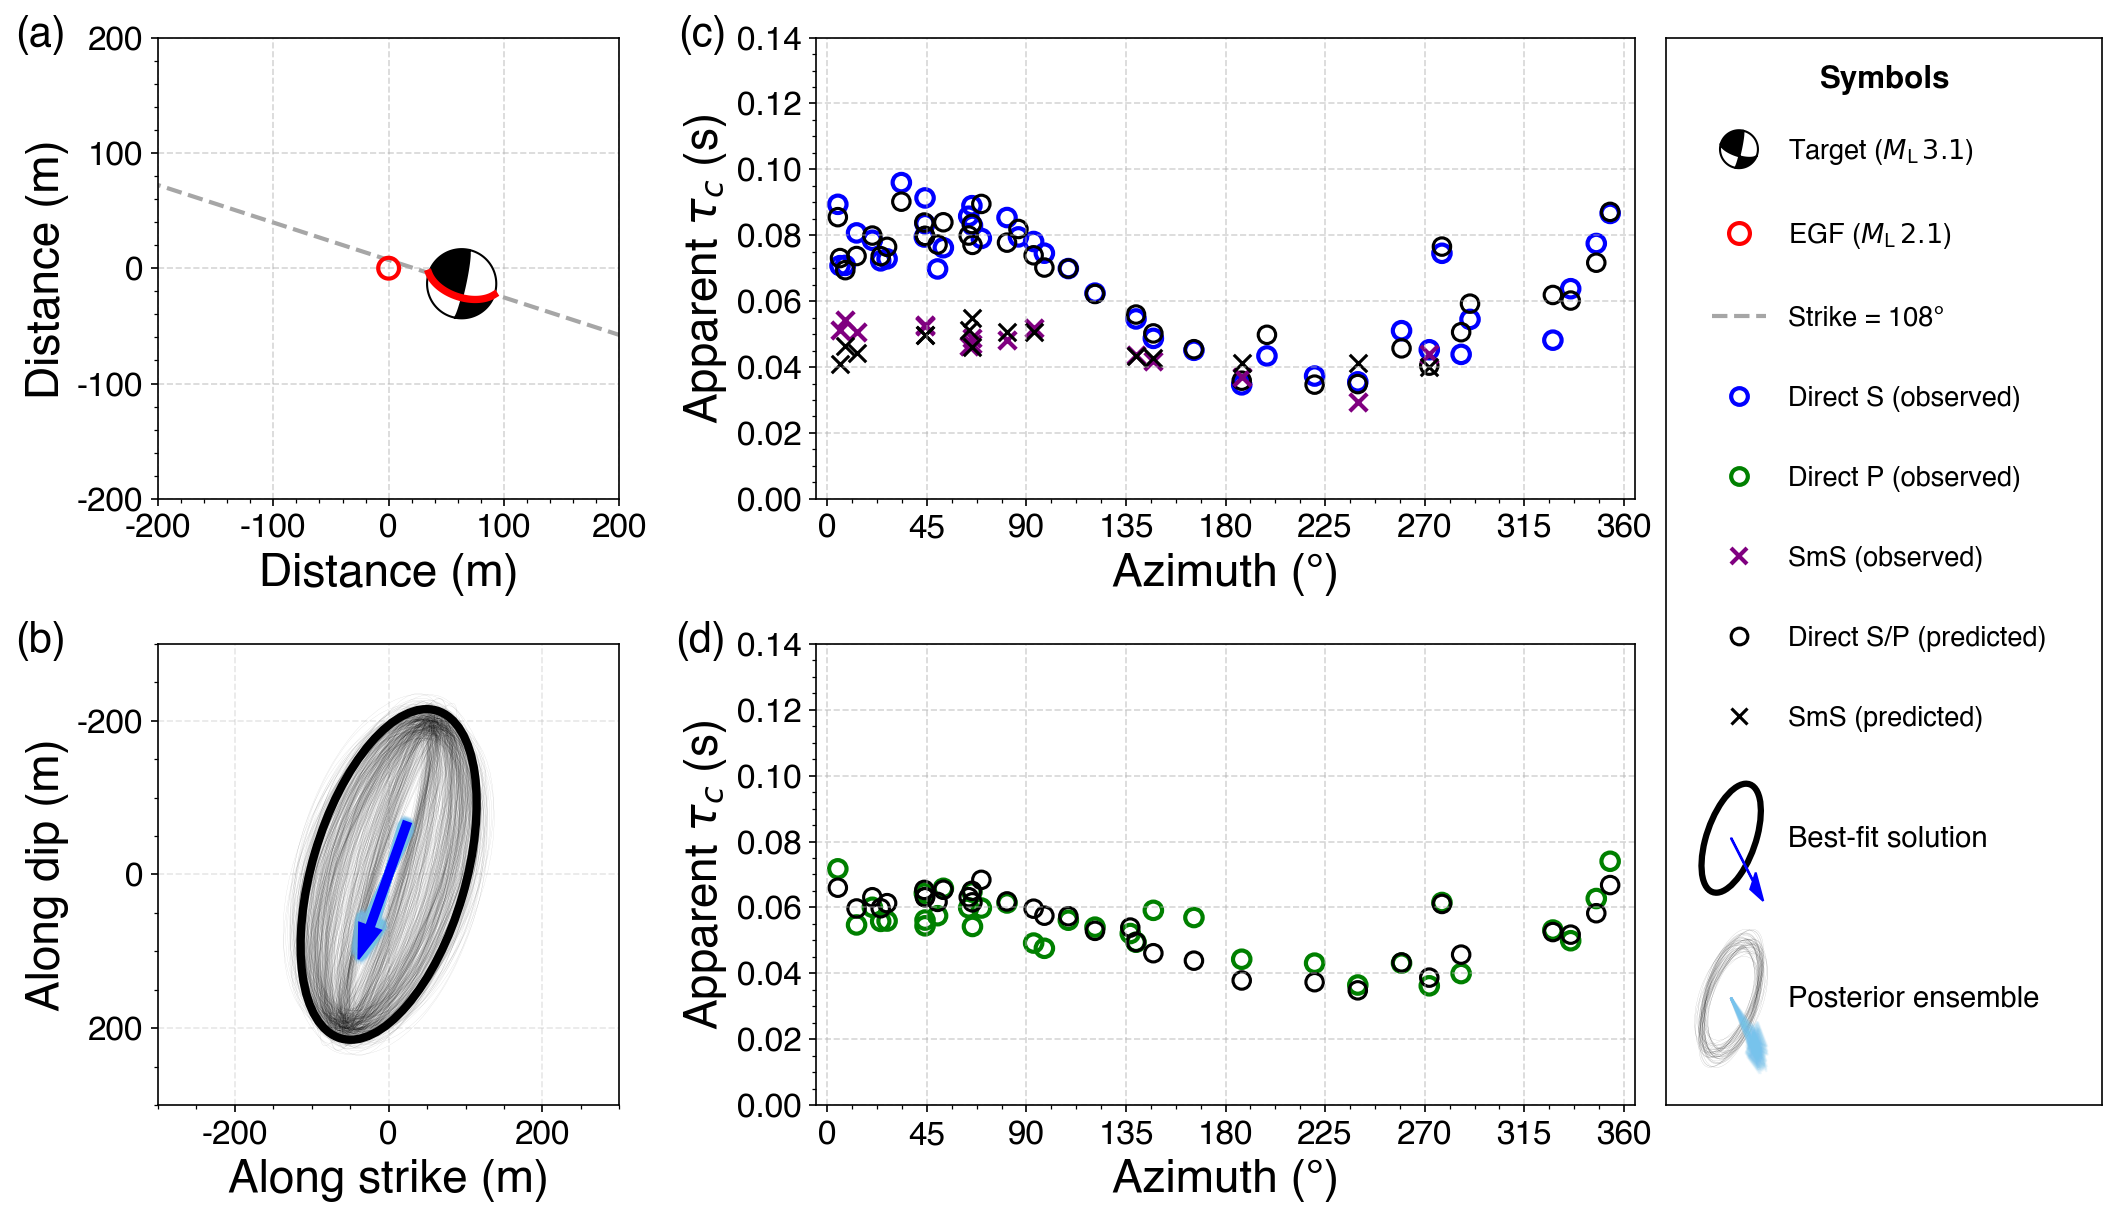

In [5]:
loc = relloc.locate(table, vp=vp * 1000, vs=vs * 1000)
offset = relative_offset(loc.azimuth, loc.dip, loc.L)
fig, axes = plot_sdm_summary(offset, (strike, dip, rake), sdp.params, post, table.azimuth, table.phase,
                             table.tauc, sdp.pred, best_label="Best-fit solution",
                             target_label=rf"Target ($M_\mathrm{{L}}\,{event['ml']}$)",
                             egf_label=rf"EGF ($M_\mathrm{{L}}\,{event['egf_ml']}$)",
                             tauc_max=0.14)      # duration axis of Fig. 4; by default it follows the data
print(f"best-fit (SDP) solution: Lc {sdp.params['Lc']:.1f} m, Wc {sdp.params['Wc']:.1f} m, "
      f"D {sdp.params['dir_ratio']:.3f}, variance reduction {sdp.vr:.1f} %")

## Step 6. Corner plot

Diagonal: marginal posterior of each parameter (kernel density, 95 % HDI shaded, MAP red, medoid orange). Below:
joint posteriors with the Pearson correlation r. Strong correlations are trade-offs: the data constrain a
combination of the two parameters better than each one alone.

stress_drop  Wc     -0.95
v0           tauc   -0.81
Wc           tauc   -0.70
stress_drop  tauc    0.64
dtype: float64

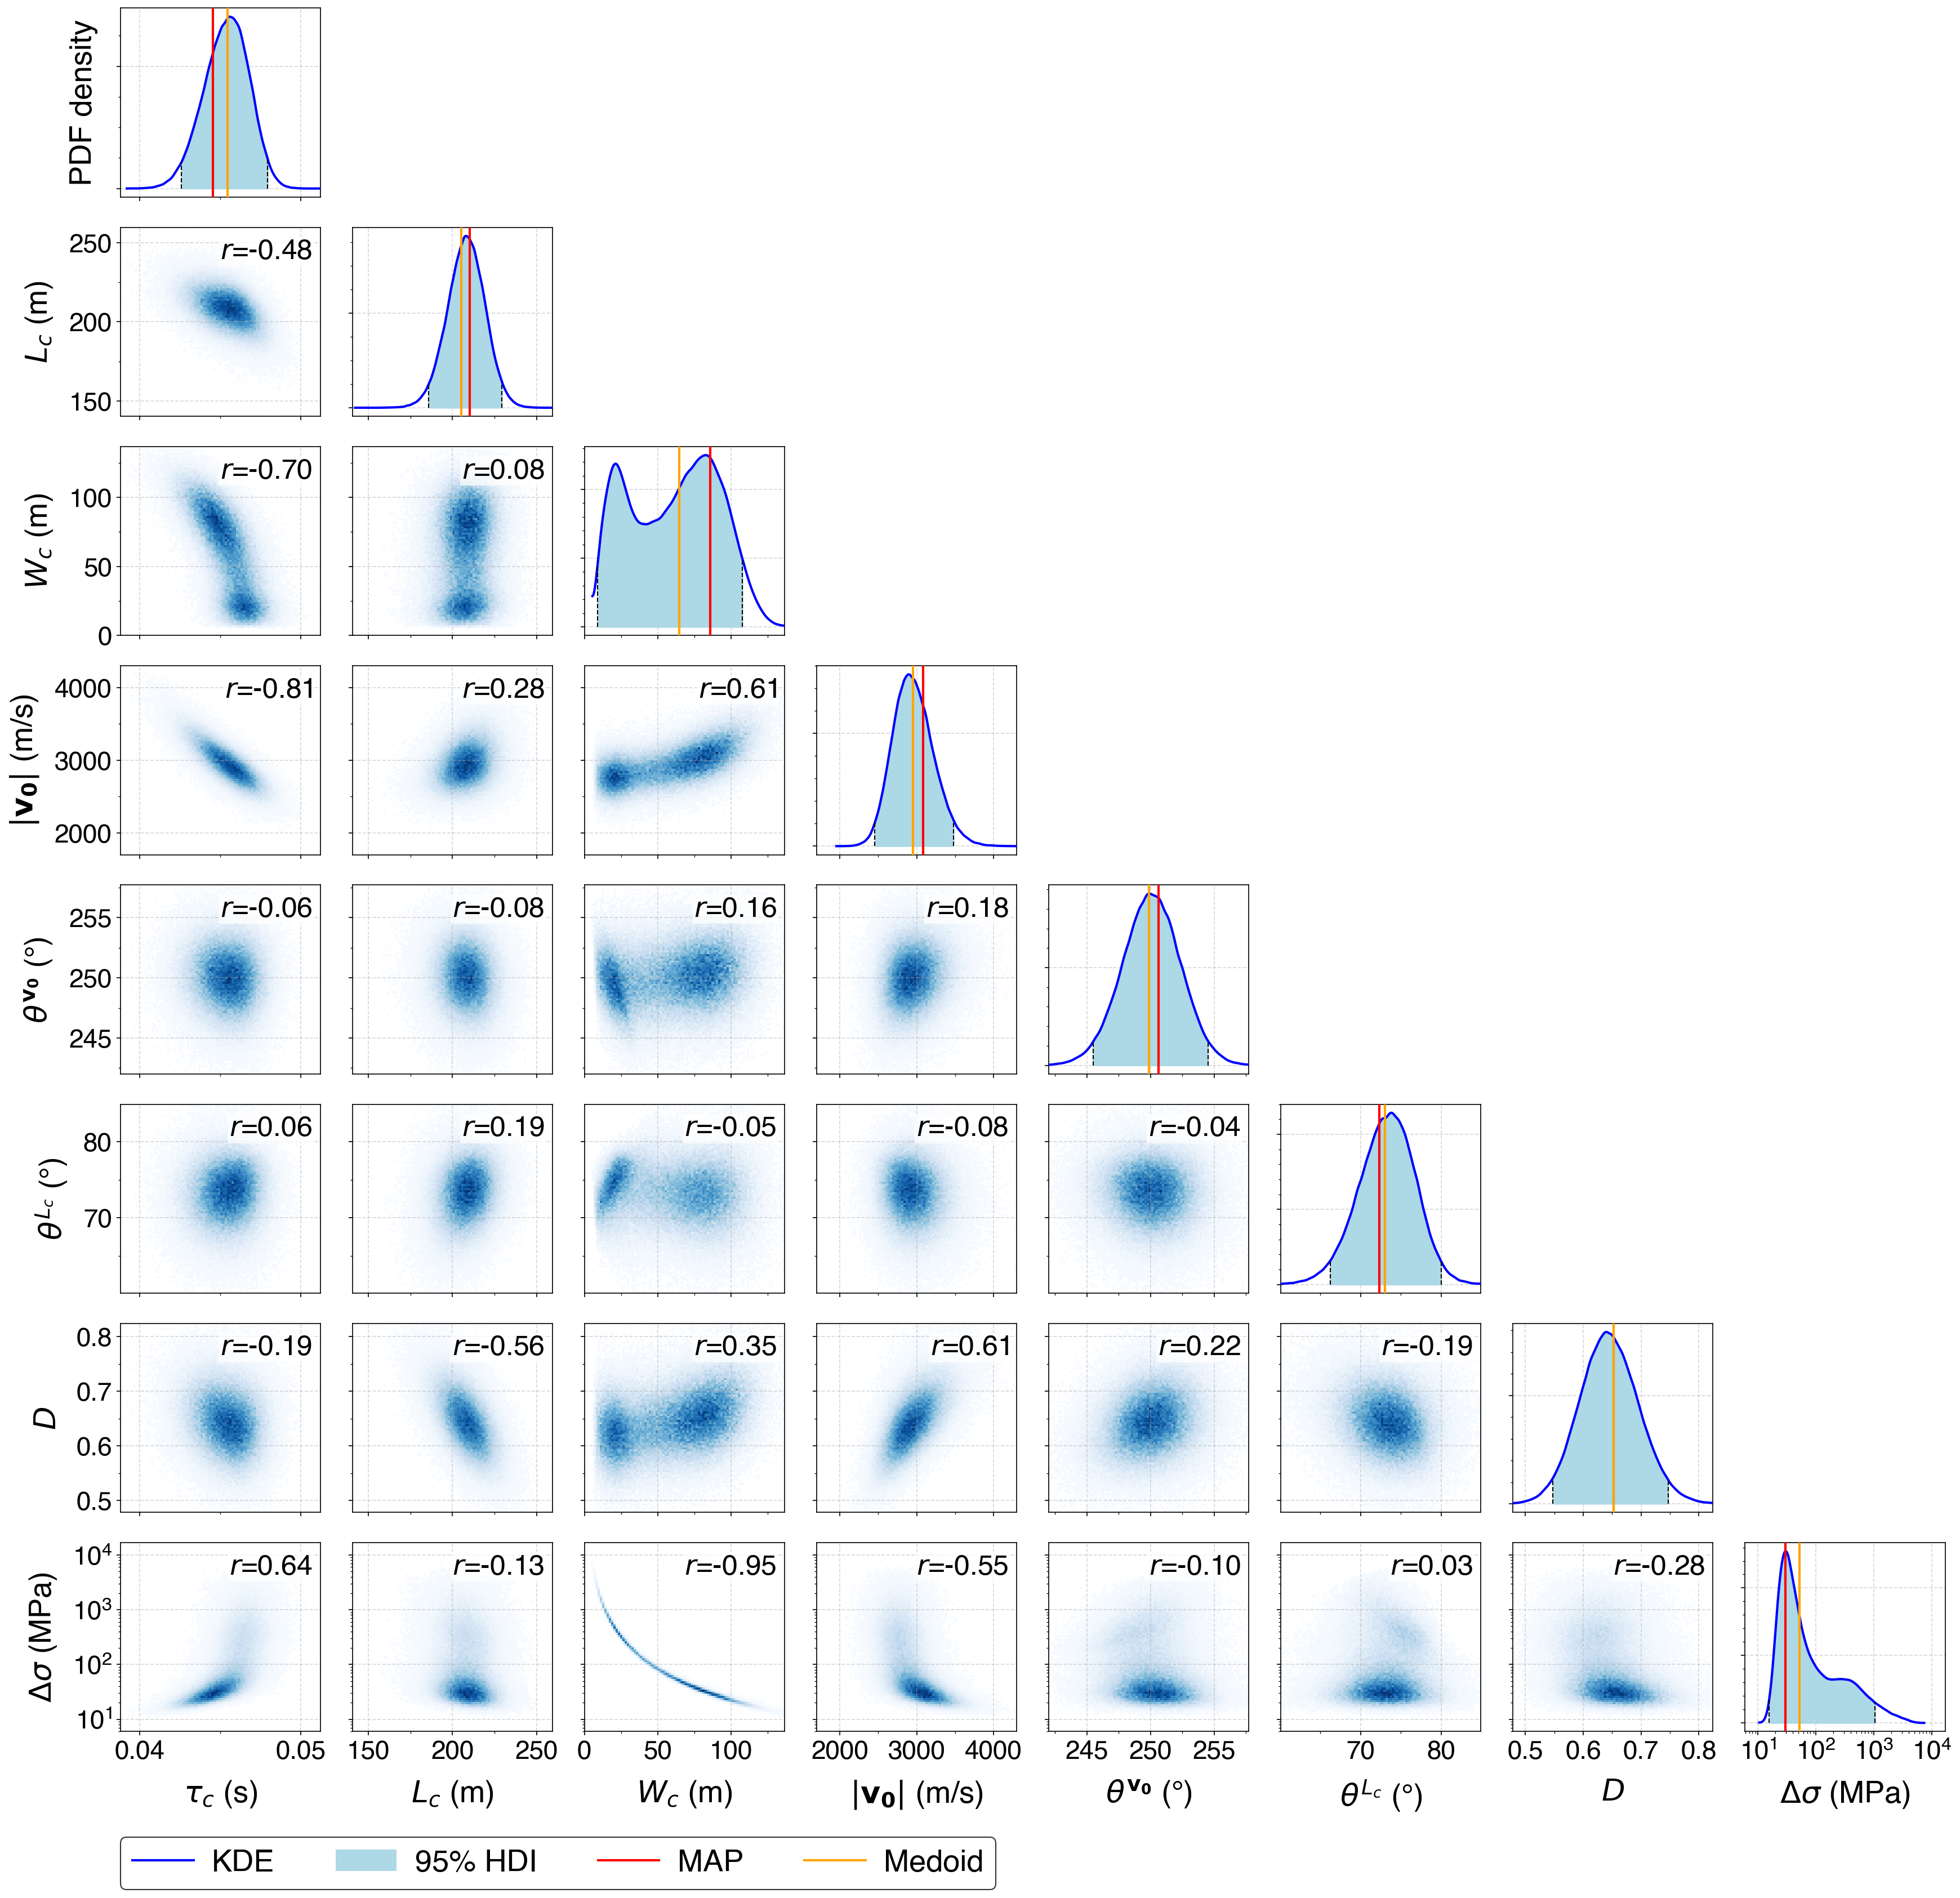

In [6]:
panels = auto_panels(post)
fig, axes = plot_corner(post, map_model, medoid, panels=panels)
r = pd.DataFrame(pearson_matrix(post, panels), index=[p.key for p in panels], columns=[p.key for p in panels])
pairs = r.where(np.tril(np.ones(r.shape, bool), -1)).stack().sort_values(key=abs, ascending=False)
pairs.head(4).round(2)

## Step 7. Fit to the data

In [7]:
res = table.assign(predicted=pred[i_med], residual=table.tauc - pred[i_med])
fit = res.groupby("phase").agg(n=("tauc", "size"), rms_residual_ms=("residual", lambda x: 1000 * np.sqrt(np.mean(x ** 2))))
print(f"variance reduction of the medoid {vr[i_med]:.1f} %, of the MAP {vr[i_map]:.1f} %, of the SDP {sdp.vr:.1f} %")
print(f"noise standard deviation (posterior median) {1000 * np.median(ensemble.std):.1f} ms")
fit.round(2)

variance reduction of the medoid 86.9 %, of the MAP 87.1 %, of the SDP 86.8 %
noise standard deviation (posterior median) 5.9 ms


,n,rms_residual_ms
phase,,
P,34,5.73
S,39,5.66
SmS,15,5.11


## Summary

In [8]:
s = summary
print(f'''Second-degree-moment inversion of the demo event
================================================
fault plane {strike:.0f}/{dip:.0f} (SDP variance reduction {sdp2.vr:.1f} % vs {sdp1.vr:.1f} % on the other plane)
posterior: {len(ensemble):,} samples, max R-hat {diag["rhat"].max():.3f}
duration tau_c {s.loc["tauc","medoid"]:.4f} s (95 % HDI {s.loc["tauc","hdi_low"]:.4f}-{s.loc["tauc","hdi_high"]:.4f})
length Lc {s.loc["Lc","medoid"]:.0f} m ({s.loc["Lc","hdi_low"]:.0f}-{s.loc["Lc","hdi_high"]:.0f}), width Wc {s.loc["Wc","medoid"]:.0f} m ({s.loc["Wc","hdi_low"]:.0f}-{s.loc["Wc","hdi_high"]:.0f})
centroid motion {s.loc["v0","medoid"]:.0f} m/s toward {s.loc["rake","medoid"]:.0f} deg from strike; directivity ratio D {s.loc["dir_ratio","medoid"]:.2f} ({s.loc["dir_ratio","hdi_low"]:.2f}-{s.loc["dir_ratio","hdi_high"]:.2f})
stress drop {s.loc["stress_drop","medoid"]:.1f} MPa ({s.loc["stress_drop","hdi_low"]:.1f}-{s.loc["stress_drop","hdi_high"]:.0f})
strongest trade-off: {pairs.index[0][0]} vs {pairs.index[0][1]}, r = {pairs.iloc[0]:+.2f}''')

Second-degree-moment inversion of the demo event
fault plane 108/58 (SDP variance reduction 86.8 % vs 53.7 % on the other plane)
posterior: 190,000 samples, max R-hat 1.001
duration tau_c 0.0454 s (95 % HDI 0.0426-0.0479)
length Lc 205 m (186-229), width Wc 65 m (9-108)
centroid motion 2950 m/s toward 250 deg from strike; directivity ratio D 0.65 (0.55-0.75)
stress drop 51.6 MPa (11.8-962)
strongest trade-off: stress_drop vs Wc, r = -0.95


## Take-home points

- The durations alone identify the fault plane when one plane fits clearly better.
- Duration, length and the direction of the centroid motion are well resolved; the width is the least resolved
  parameter, and the stress drop inherits its uncertainty (the strongest correlation in the corner plot).
- The medoid, the MAP and the SDP solution describe the same rupture; the posterior shows how far the data allow
  it to vary.
- Sampling the noise level lets the data decide how closely the durations should be fitted.